<div style="border-left:5px solid #67CBEE;padding:10px 16px;background:#F7F9FB;color:#19222D;margin:12px 0"><b>AMD Radeon · YOLO26 · Day 01</b><br><span style="color:#536273">算法 → 数据 → 训练 → 评测 → 证据。每一个结论都应由实际运行结果支撑。</span><br><span style="color:#536273">Algorithm → Data → Training → Evaluation → Evidence. Every conclusion must be backed by real execution results.</span></div>

# 03 / Lab C · ROCm GPU 训练、微调与 Loss

**建议时长：50–70 分钟**　｜　学习路径：预训练权重 → 前后向训练 → 模型工件

> 请按顺序运行；运行结果必须来自自己的 GPU 环境，不可把示例文字当作实测数据。

---

# 03 / Lab C · ROCm GPU Training, Fine-tuning & Loss

**Suggested time: 50–70 minutes** | Learning path: pretrained weights → forward/backward training → model artifacts

> Run the cells in order; every result must come from your own GPU environment — never present the sample text as measured data.

> ### 运行前 30 秒：确认 Kernel 选对了
> 本课程全部 Notebook 必须运行在 **`YOLO26 - AMD ROCm 7.14.1`** 内核上（看页面右上角的内核名）。
>
> - **怎么选**：菜单 **Kernel → Change Kernel → YOLO26 - AMD ROCm 7.14.1**（JupyterLab 点右上角内核名）。
> - **怎么确认**：运行第一个代码格后，`torch_hip` 是版本号而非 `None`，并打印出你的 AMD 显卡名。
> - **选错会怎样**：00 会被 ROCm 门禁当场拦截；若误用平台默认 `python3`，可能到 Lab A 才报出难懂的 `NotImplementedError`。
> - **列表里没有这个内核？** 在项目目录执行一次注册：
>   `.venv/bin/python -m ipykernel install --user --name yolo26-rocm7141 --display-name "YOLO26 - AMD ROCm 7.14.1"`
>   （Windows 见 `docs/ROCM_WINDOWS_SETUP.md`；Linux 见 `docs/RADEON_CLOUD_LINUX_SETUP.md` §2B）

---

> ### 30 seconds before you run: make sure the Kernel is right
> Every notebook in this course must run on the **`YOLO26 - AMD ROCm 7.14.1`** kernel (see the kernel name at the top right).
>
> - **How to select**: menu **Kernel → Change Kernel → YOLO26 - AMD ROCm 7.14.1** (JupyterLab: click the kernel name at the top right).
> - **How to confirm**: after the first code cell, `torch_hip` is a version string (not `None`) and your AMD GPU name is printed.
> - **What if you pick the wrong one**: Lab 00's ROCm gate stops you immediately; with the platform default `python3` you may instead hit an opaque `NotImplementedError` deep inside Lab A.
> - **Kernel not in the list?** Register it once from the project directory:
>   `.venv/bin/python -m ipykernel install --user --name yolo26-rocm7141 --display-name "YOLO26 - AMD ROCm 7.14.1"`
>   (Windows: `docs/ROCM_WINDOWS_SETUP.md`; Linux: `docs/RADEON_CLOUD_LINUX_SETUP.md` §2B)

### 学习地图（30 秒看完这张表再开始）

| 问题 | 答案 |
|---|---|
| 为什么学这个？ | 训练把"会用模型"变成"会造模型"；读懂 Loss 曲线是分水岭 |
| 需要先懂什么？ | 完成 00（权重缓存）与 02（数据集登记） |
| 我修改哪个参数？ | 课堂保持默认（12 Epoch 是全组统一基线）；课后可试 `epochs`/`imgsz` 并记录理由 |
| 成功长什么样？ | 冒烟几十秒完成；曲线 loss 整体降、mAP 整体升；`best.pt` 生成 |
| 失败怎么自救？ | 本页常见错误表；训练"看似卡住"多半是 JIT 预热（见下方等待说明） |
| 保存什么证据？ | best.pt + SHA256、results.csv/png、训练配置 JSON |
| 求职价值？ | "我在 AMD ROCm 上真机微调过 YOLO" + 完整复现链 |

---

### Lab Map (read this 30-second table first)

| Question | Answer |
|---|---|
| Why learn this? | Training turns "can use a model" into "can build one"; reading loss curves is the watershed |
| Prerequisites? | Lab 00 (weight cache) and Lab 02 (registered dataset) |
| What do I change? | Keep defaults in class (12 epochs is the shared baseline); after class try `epochs`/`imgsz` and record why |
| What does success look like? | Smoke finishes in tens of seconds; loss trends down, mAP up; `best.pt` appears |
| If it fails? | The common-errors table; a "stuck" training is usually JIT warm-up (see the wait note below) |
| Evidence to save? | best.pt + SHA256, results.csv/png, the training-config JSON |
| Job value? | "I fine-tuned YOLO on real AMD ROCm hardware" with a full reproduction chain |

## 实验目标
1. 在真实 AMD ROCm GPU 上运行 YOLO26n 预训练模型微调。
2. 先用 COCO8（4 train + 4 val）做**训练链路冒烟**，再训练 Lab B 数据。
3. 保存运行条件、`best.pt`、`last.pt`、训练曲线与 SHA256。
4. 解释 Loss、Epoch、Batch、学习率、过拟合和泛化；不得把 Smoke 成绩说成工业精度。

**依赖**：先完成 00（权重缓存）与 02（数据集登记）。需要 GPU 与时间；推荐课前缓存模型/数据。

**注意**：`amp=False` 仅作 ROCm AMP 异常排查，不应在没有问题时随意更改对照配置。

### 预期输出（看形状，不是标准答案数字）
- 冒烟格几分钟内完成并打印 `GPU smoke completed`。
- 正式训练逐 epoch 打印进度；结束后 `runs/lab_c/baseline/` 下出现 `weights/best.pt`、`weights/last.pt`、`results.csv`（每 epoch 一行）、`results.png`。
- `results.png` 里 **train loss 各列整体下降**、mAP 相关列整体上升——小数据集上会抖动，方向比光滑更重要。
- 验证格打印一个含 `precision / recall / mAP50 / mAP50_95` 的字典，并明确标注 `split: val`。

### 常见错误与下一步
| 症状 | 原因 | 下一步 |
|---|---|---|
| `先完成 02 Lab B` 断言失败 | course_config 里没有数据集 | 先跑 02，或设 `YOLO_USER_DATA_YAML` |
| 训练出现 NaN | AMP/数值问题或数据有坏标签 | 保持 `amp=False` 重试；用 02 的 QA 复查标签 |
| `torchvision GPU NMS` 报错 | 平台栈缺 NMS 内核 | 部署文档 §2B 自建隔离栈 |
| 显存不足 OOM | batch 过大或 imgsz 过大 | 本课程配置在 48GB 卡上余量充足；改配置前先记录并说明理由 |

---

## Goal
1. Fine-tune the YOLO26n pretrained model on a real AMD ROCm GPU.
2. **Smoke-test the training pipeline** on COCO8 (4 train + 4 val) first, then train on the Lab B dataset.
3. Persist run conditions, `best.pt`, `last.pt`, training curves and SHA256 hashes.
4. Explain loss, epochs, batches, learning rate, overfitting and generalization; never dress smoke-run numbers up as industrial accuracy.

**Prerequisite**: finish 00 (weight cache) and 02 (dataset registration). This lab needs a GPU and time; pre-caching model/data before class is recommended.

**Note**: `amp=False` exists for ROCm AMP troubleshooting only — do not flip comparison configs without a diagnosed problem.

### Expected Output (shape, not ground-truth numbers)
- The smoke cell finishes within minutes and prints `GPU smoke completed`.
- Full training prints per-epoch progress; afterwards `runs/lab_c/baseline/` contains `weights/best.pt`, `weights/last.pt`, `results.csv` (one row per epoch) and `results.png`.
- In `results.png` the **train-loss columns trend down** and the mAP columns trend up — on a tiny dataset they wobble; direction matters more than smoothness.
- The validation cell prints a dict with `precision / recall / mAP50 / mAP50_95`, clearly tagged `split: val`.

### Common Errors & Next Steps
| Symptom | Cause | Next step |
|---|---|---|
| assertion `先完成 02 Lab B` fires | no dataset in course_config | run 02 first, or set `YOLO_USER_DATA_YAML` |
| NaN during training | AMP/numeric issue or bad labels | keep `amp=False` and retry; re-run 02 QA on labels |
| `torchvision GPU NMS` error | platform stack lacks the NMS kernel | build the isolated stack (setup guide §2B) |
| CUDA OOM | batch/imgsz too large | the course config fits comfortably in 48 GB; record and justify any change |

In [10]:
from pathlib import Path
import os
import sys
import json

candidates = [Path.cwd(), Path.cwd().parent, Path('/workspace/YOLO26_ROCm_Day1_Labs')]
package = next((p for p in candidates if (p / 'course/lab_utils.py').exists()), None)
if package is None:
    raise FileNotFoundError('请先将 ZIP 完整解压，并从项目目录或 notebooks/ 目录启动 Jupyter。')
sys.path.insert(0, str(package))
from course.lab_utils import (root, ensure_dirs, load_config, save_config, write_json,
                              write_csv, system_info, require_rocm, sha256)

home = ensure_dirs()
cfg = load_config()
print('Project:', package, '\nPersistent output:', home)

Project: /workspace/yolo26-rocm-day1-labs 
Persistent output: /workspace/yolo_course


In [11]:
from course.lab_utils import get_metrics_summary
import torch
import time
from ultralytics import YOLO

device = require_rocm()
assert cfg['dataset_yaml'] and Path(cfg['dataset_yaml']).is_file(), \
    '先完成 02 Lab B，或设置 YOLO_USER_DATA_YAML'
model_initial = (str(home / 'artifacts/yolo26n.pt')
                 if (home / 'artifacts/yolo26n.pt').is_file() else cfg['model'])
print('Training:', model_initial, 'dataset:', cfg['dataset_yaml'])

AMD ROCm verified: AMD Radeon Pro W7900D HIP: 7.14.60850
Training: /workspace/yolo_course/artifacts/yolo26n.pt dataset: /workspace/yolo_course/data/processed/coco128_classroom_3class/data.yaml


### 训练开始后的正常现象（等待时看这里）
- 每个 Epoch 打印一行进度（各项 loss 与耗时）；W7900 级别显卡上 12 Epoch 约 **30–100 秒**。
- **首次运行前 ~1 分钟可能"看似卡住"**——那是 MIOpen 在编译 GPU kernel（一次性编译，之后全机共享缓存，第二次起不再出现）。想确认它在干活，可在另一个终端运行 `rocm-smi` 观察 GPU 利用率。
- 请不要中断训练；等待期间正好阅读下面的思考题。

---

### What to expect while training runs (read while you wait)
- One progress line per epoch (losses and time); on a W7900-class GPU, 12 epochs take roughly **30–100 seconds**.
- **The first run may look frozen for ~1 minute** — that is MIOpen compiling GPU kernels (a one-time cost shared machine-wide afterwards). Run `rocm-smi` in another terminal to watch the GPU working.
- Do not interrupt; the wait is the perfect time to read the questions below.

In [12]:
# 非正式数据集，验证 GPU 实际能跑 Forward/Backward，不用于发布精度成绩。
RUN_SMOKE = True
if RUN_SMOKE:
    smoke_model = YOLO(model_initial)
    smoke_model.train(data='coco8.yaml', epochs=1, imgsz=320, batch=4, device=device,
                      workers=0, amp=False, project=str(home / 'runs/lab_c'), name='smoke',
                      exist_ok=True, plots=False, seed=42)
    print('GPU smoke completed; COCO8 is not a benchmark.')

Ultralytics 8.4.199 🚀 Python-3.12.13 torch-2.12.0+rocm7.14.1 CUDA:0 (AMD Radeon Pro W7900D, 49136MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/workspace/yolo_course/artifacts/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke, nbs=64, nms=None, opse

In [13]:
# 正式教学训练。为了让学生在课上完成闭环，默认 12 Epoch；高质量结果需课后延长训练。
RUN_BASELINE = True
BASELINE_EPOCHS = 12
train_kwargs = dict(data=cfg['dataset_yaml'], epochs=BASELINE_EPOCHS,
                    imgsz=512, batch=8, device=device, workers=0, patience=30,
                    optimizer='SGD', seed=42, deterministic=False,
                    amp=False, plots=True, project=str(home / 'runs/lab_c'),
                    name='baseline', exist_ok=True)
if RUN_BASELINE:
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    baseline = YOLO(model_initial)
    train_output = baseline.train(**train_kwargs)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    peak_gib = torch.cuda.max_memory_allocated() / 2**30
    run_dir = Path(baseline.trainer.save_dir).resolve()
    weights = run_dir / 'weights/best.pt'
    assert weights.exists(), f'best.pt missing: {weights}'
    record = {'run_dir': str(run_dir), 'weights': str(weights), 'sha256': sha256(weights),
              'elapsed_seconds': round(elapsed, 2), 'peak_allocated_GiB': round(peak_gib, 3),
              'args': train_kwargs, 'system': system_info(),
              'warning': 'Peak memory is PyTorch allocated memory, not total device VRAM.'}
    write_json(home / 'reports/lab_c_baseline.json', record)
    save_config({'baseline_run': str(run_dir), 'baseline_weights': str(weights),
                 'baseline_train_settings': train_kwargs})
    print(record)
else:
    print('未执行训练。后续实验需要一个经过验证的 best.pt，请不要伪造训练结果。')

Ultralytics 8.4.199 🚀 Python-3.12.13 torch-2.12.0+rocm7.14.1 CUDA:0 (AMD Radeon Pro W7900D, 49136MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/yolo_course/data/processed/coco128_classroom_3class/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/workspace/yolo_course/artifacts/yolo26n.pt, momentum=0.937,

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
7,8,16.5836,1.46232,1.32192,0.01108,0.43706,0.42864,0.43006,0.26359,1.84881,1.56285,0.01818,0.004225,0.004225,0.004225
8,9,18.7426,1.50570,1.35677,0.01162,0.38087,0.44828,0.47999,0.25596,2.03421,1.59102,0.02067,0.003400,0.003400,0.003400
9,10,20.7912,1.64673,1.24598,0.01046,0.36613,0.51724,0.46002,0.25351,2.04981,1.56912,0.02235,0.002575,0.002575,0.002575
10,11,22.8312,1.52820,1.37769,0.01123,0.40943,0.51724,0.47044,0.25313,1.91753,1.61937,0.01918,0.001750,0.001750,0.001750
11,12,24.8707,1.51238,1.31376,0.00976,0.46696,0.51364,0.49168,0.26116,1.91266,1.54271,0.01854,0.000925,0.000925,0.000925


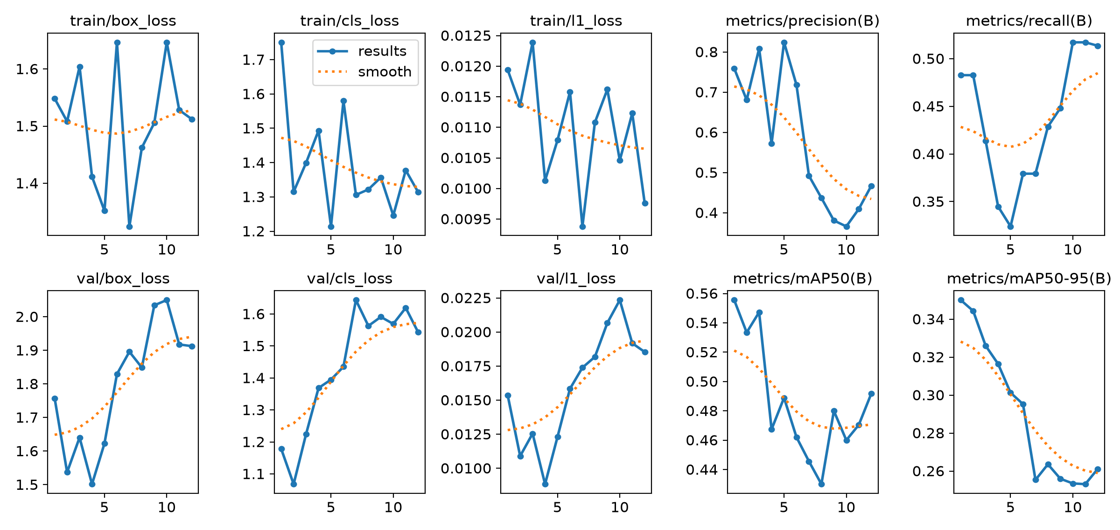

In [14]:
# 阅读训练工件：不同版本可能输出不同的列名，请以实际 CSV 为准。
from PIL import Image
import pandas as pd

cfg = load_config()
run_dir = Path(cfg['baseline_run'])
csv_path = run_dir / 'results.csv'
if csv_path.exists():
    history = pd.read_csv(csv_path)
    display(history.tail(5))
else:
    print('Missing results.csv:', csv_path)
if (run_dir / 'results.png').exists():
    display(Image.open(run_dir / 'results.png').resize((1120, 530)))

In [15]:
# 不混淆验证集与最终测试集：首次使用 split='val'
cfg = load_config()
best = YOLO(cfg['baseline_weights'])
metrics = best.val(data=cfg['dataset_yaml'], split='val', device=device,
                   imgsz=640, batch=8, workers=0, plots=True, verbose=False)
summary = get_metrics_summary(metrics)
summary['split'] = 'val'
summary['model_sha256'] = sha256(Path(cfg['baseline_weights']))
write_json(home / 'reports/lab_c_baseline_val.json', summary)
print('Validation only (NOT test):', summary)

Ultralytics 8.4.199 🚀 Python-3.12.13 torch-2.12.0+rocm7.14.1 CUDA:0 (AMD Radeon Pro W7900D, 49136MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2405.2±1068.1 MB/s, size: 69.6 KB)
val: Scanning /workspace/yolo_course/data/processed/coco128_classroom_3class/labels/val.cache... 20 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 14.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 22.0it/s 0.1s.2s
                   all         20         29      0.839      0.552      0.624      0.383
Speed: 0.1ms preprocess, 2.5ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /workspace/yolo26-rocm-day1-labs/runs/detect/val-26
Validation only (NOT test): {'precision': 0.8394751789338629, 'recall': 0.5517241379310345, 'mAP50': 0.6237316111766408, 'mAP50_95': 0.38295583016361323, 'split': 'val', 'model_sha256': '

### 练习：读懂你自己的训练曲线（先判断，再验证）
训练不是"跑完就结束"。打开上面 `results.csv` 的最后几行和 `results.png`，**自己**回答三个问题：
1. train 的 box_loss 从第 1 到第 12 个 epoch 大致怎么变？
2. 验证集 mAP50 怎么变？
3. 以你的数字为证据：过拟合了吗？为什么？

下面的练习格**默认可直接运行**——它会打印你自己 results.csv 的首末行真实数字。用这些数字把 `MY_READING` 三问答完（替换 TODO）再跑一次保存。你的判断会在 Lab D 与官方验证指标对照——写错完全没关系，用证据下结论才是目的；填写状态记入 `filled` 字段。

---

### Try It Yourself: read your own training curve (judge first, verify later)
Training is not "run and done". Open the tail of `results.csv` above and `results.png`, and answer three questions **yourself**:
1. How did train box_loss move from epoch 1 to 12?
2. How did validation mAP50 move?
3. With your numbers as evidence: is the model overfitting? Why?

The practice cell below **runs by default** — it first prints the real numbers from your own results.csv. Answer the three questions using them (replace the TODOs), then run again to save. Lab D will confront your reading with the official metrics — being wrong is fine; concluding from evidence is the point, and the `filled` flags record whether you did.

In [16]:
# 学生练习：读曲线（默认可直接运行——先看真实数字，再写下你的判断）
import csv

MY_READING = {
    'train_box_loss_epoch1_to_12': 'TODO: box_loss 从第 1 到第 12 个 epoch 大致如何变化？引用两个数字',
    'val_mAP50_trend': 'TODO: 验证集 mAP50 大致如何变化？引用两个数字',
    'overfitting_call': 'TODO: 以你的曲线为证据，过拟合了吗？为什么？',
}
# 无人值守复验通道（学生不需要）：YOLO_PRACTICE_FILL 指向 JSON 可注入已填写样例
if os.environ.get('YOLO_PRACTICE_FILL'):
    _p = Path(os.environ['YOLO_PRACTICE_FILL'])
    if _p.is_file():
        for _k, _v in json.loads(_p.read_text(encoding='utf-8')).get('lab_c_my_reading', {}).items():
            MY_READING[_k] = _v
filled = {key: not str(value).startswith('TODO') for key, value in MY_READING.items()}
with (Path(cfg['baseline_run']) / 'results.csv').open(encoding='utf-8') as f:
    rows = list(csv.DictReader(f))
first, last = rows[0], rows[-1]
print('你的 epoch 数:', len(rows), '| 首行/末行 epoch:', first.get('epoch'), '/', last.get('epoch'))
print('train/box_loss: 首行 =', first.get('train/box_loss'), '| 末行 =', last.get('train/box_loss'))
print('mAP50:         首行 =', first.get('metrics/mAP50(B)'), '| 末行 =', last.get('metrics/mAP50(B)'))
print('val/box_loss:  首行 =', first.get('val/box_loss'), '| 末行 =', last.get('val/box_loss'))
if not all(filled.values()):
    print('提示：三问还没作答（TODO 未替换）。上面就是你自己的 results.csv 真实数字——用它们把 '
          'MY_READING 填完再运行一次，保存你的结论。Lab D 会用官方指标对照你的判断。')
write_json(home / 'reports/lab_c_my_reading.json', {**MY_READING, 'filled': filled})

你的 epoch 数: 12 | 首行/末行 epoch: 1 / 12
train/box_loss: 首行 = 1.54837 | 末行 = 1.51238
mAP50:         首行 = 0.55556 | 末行 = 0.49168
val/box_loss:  首行 = 1.75721 | 末行 = 1.91266
提示：三问还没作答（TODO 未替换）。上面就是你自己的 results.csv 真实数字——用它们把 MY_READING 填完再运行一次，保存你的结论。Lab D 会用官方指标对照你的判断。


### 为什么基线固定训练用 `imgsz=512`，评测用 `imgsz=640`？
训练输入尺寸属于训练方案，下一步 Lab E 会只改变训练尺寸；为了公平比较两组模型，Lab E 会用同一个 `imgsz=640` 做评测。这是一种课堂控制变量方案，不是所有工业评测任务必须如此。

### 思考题 / 面试必答
1. `best.pt` 与 `last.pt` 有什么区别？
2. 为什么训练 Loss 下降不能证明模型在新场景一定更好？
3. `torch.version.hip` 与 `torch.cuda.is_available()` 分别证明什么？
4. 如果 AMP 检查/训练有 NaN，你会怎样排查并记录配置变动？

**交付**：`runs/lab_c/baseline/`、`reports/lab_c_baseline.json`、`lab_c_baseline_val.json`。

---

### Why does the baseline train at `imgsz=512` but evaluate at `imgsz=640`?
Training input size is part of the training recipe — Lab E will vary exactly this knob. To compare both arms fairly, Lab E evaluates every model with the same `imgsz=640`. This is a classroom controlled-variable design, not a universal industrial rule.

### Think / Interview Questions
1. What is the difference between `best.pt` and `last.pt`?
2. Why doesn't a falling training loss prove the model is better on new scenes?
3. What do `torch.version.hip` and `torch.cuda.is_available()` each prove?
4. If the AMP check or training produces NaN, how do you troubleshoot and record the config change?

**Deliverables**: `runs/lab_c/baseline/`, `reports/lab_c_baseline.json`, `lab_c_baseline_val.json`.